# PFA – Sujet 09 : Détection de fraude bancaire par TabM compact

**Thème :** Fraude · **Dataset :** Credit Card Fraud Detection (ULB / MLG, Kaggle)

**Objectif :** détecter les transactions frauduleuses à partir de variables tabulaires anonymisées et étudier l'apport
d'un petit ensemble de réseaux à poids partagés (TabM) par rapport à une régression logistique et à un MLP.

| Rôle | Modèle |
|---|---|
| Référence 1 | Régression logistique (pondération des classes calculée sur le train) |
| Référence 2 | MLP 30-64-64-1, ReLU, dropout 0,1, sortie logit, BCE pondérée |
| Modèle principal | TabM compact : `n_blocks=2, d_block=64, k=4, dropout=0.1, d_out=1`, sans embeddings numériques, BCE pondérée |
| Ablation | Même TabM **sans** pondération de la BCE |

**Structure du notebook (points de contrôle de la fiche)**
1. **Comprendre** – données, colonnes, effectifs
2. **Préparer** – coupure chronologique 70/15/15, mise à l'échelle, références
3. **Construire** – MLP, TabM pondéré, ablation
4. **Comparer** – seuils figés sur validation, métriques et matrices de confusion sur le test
5. **Restituer** – analyse des erreurs, sauvegarde des résultats et conclusion

> Règles respectées : aucun poids pré-entraîné ; toute statistique (mise à l'échelle, poids de classe, seuil)
> est calculée sur le **train** ou la **validation**, jamais sur le test.

## 0. Installation et configuration

In [1]:
# Installation de TabM si absent (Colab dispose déjà de torch, sklearn, pandas, matplotlib)
import importlib.util
import subprocess
import sys

if importlib.util.find_spec('tabm') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'tabm'])

In [2]:
import json
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             precision_recall_curve, precision_score, recall_score)
from sklearn.preprocessing import StandardScaler
from tabm import TabM

# Sur Colab, Google Drive sert à conserver données, checkpoints et résultats entre les sessions
try:
    from google.colab import drive
    EN_COLAB = True
except ImportError:
    EN_COLAB = False
if EN_COLAB:
    drive.mount('/content/drive')
    RACINE = Path('/content/drive/MyDrive/PFA_fraude')
else:
    RACINE = Path('.').resolve()

DATA_DIR = RACINE / 'data'
CKPT_DIR = RACINE / 'checkpoints'
RES_DIR = RACINE / 'resultats'
for d in (DATA_DIR, CKPT_DIR, RES_DIR):
    d.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Racine :', RACINE, '| Device :', DEVICE)

Racine : D:\antigravity\PFA | Device : cpu


In [3]:
# Configuration unique de l'expérience : elle est enregistrée avec les résultats
CFG = {
    'seed': 42,
    'fractions': [0.70, 0.15, 0.15],   # train / validation / test, coupure chronologique
    'batch_size': 1024,
    'lr': 1e-3,
    'weight_decay': 1e-4,
    'max_epochs': 50,
    'patience': 8,                      # arrêt anticipé sur l'Average Precision de validation
    'mlp': {'hidden': [64, 64], 'dropout': 0.1},
    'tabm': {'n_blocks': 2, 'd_block': 64, 'k': 4, 'dropout': 0.1, 'd_out': 1},
    'regle_seuil': 'seuil maximisant le F1 sur la validation',
}


def fixer_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


fixer_seed(CFG['seed'])

In [4]:
# Suivi des expériences avec MLflow (facultatif : le notebook fonctionne aussi sans)
# Interface : `mlflow ui --backend-store-uri sqlite:///mlflow.db` lancé depuis la racine du projet
USE_MLFLOW = importlib.util.find_spec('mlflow') is not None
EXPERIENCE = 'PFA-fraude-TabM'
RUNS = {}   # nom du modèle -> identifiant du run MLflow

if USE_MLFLOW:
    import mlflow
    mlflow.set_tracking_uri(f"sqlite:///{(RACINE / 'mlflow.db').as_posix()}")
    if mlflow.get_experiment_by_name(EXPERIENCE) is None:
        mlflow.create_experiment(EXPERIENCE, artifact_location=(RACINE / 'mlartifacts').as_uri())
    mlflow.set_experiment(EXPERIENCE)


def journaliser_run(nom, params, historique=(), metriques=None):
    # Un seul run par modèle : son identifiant est mémorisé à côté des checkpoints pour éviter les doublons à la relance
    if not USE_MLFLOW:
        return
    fichier = CKPT_DIR / nom / 'mlflow_run_id.txt'
    fichier.parent.mkdir(parents=True, exist_ok=True)
    if fichier.exists():
        try:
            RUNS[nom] = mlflow.get_run(fichier.read_text().strip()).info.run_id
            return
        except Exception:
            pass   # base MLflow supprimée : on recrée le run
    with mlflow.start_run(run_name=nom) as run:
        mlflow.log_params(params)
        for h in historique:
            mlflow.log_metrics({'loss_train': h['loss_train'], 'ap_val': h['ap_val']}, step=h['epoch'])
        if metriques:
            mlflow.log_metrics(metriques)
    fichier.write_text(run.info.run_id)
    RUNS[nom] = run.info.run_id


print('MLflow actif :', USE_MLFLOW)

MLflow actif : True


## 1. Comprendre les données

Le fichier `creditcard.csv` contient : `Time` (secondes depuis la première transaction), `Amount`,
`V1`…`V28` (composantes PCA **déjà fournies** par l'éditeur ; on ne les reconstruit pas) et `Class` (0 normale, 1 fraude).

**Téléchargement** – deux options :
- déposer `creditcard.csv` dans `MyDrive/PFA_fraude/data/` ;
- ou laisser `kagglehub` le télécharger (identifiants Kaggle requis : `KAGGLE_USERNAME` / `KAGGLE_KEY`).

In [5]:
CSV = DATA_DIR / 'creditcard.csv'
if not CSV.exists():
    if importlib.util.find_spec('kagglehub') is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'kagglehub'])
    import kagglehub
    chemin = Path(kagglehub.dataset_download('mlg-ulb/creditcardfraud'))
    CSV = chemin / 'creditcard.csv'

df = pd.read_csv(CSV)
FEATURES = ['Time', 'Amount'] + [f'V{i}' for i in range(1, 29)]
CIBLE = 'Class'
assert set(FEATURES + [CIBLE]) <= set(df.columns)

print('Dimensions :', df.shape)
print('Valeurs manquantes :', int(df.isna().sum().sum()))
print('Lignes dupliquées :', int(df.duplicated().sum()))
print(df[CIBLE].value_counts().rename({0: 'normale', 1: 'fraude'}))
print(f"Taux de fraude : {df[CIBLE].mean():.4%}")
df.head()

Dimensions : (284807, 31)
Valeurs manquantes : 0
Lignes dupliquées : 1081
Class
normale    284315
fraude        492
Name: count, dtype: int64
Taux de fraude : 0.1727%


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Accuracy du classifieur trivial « toujours normale » : 99.8273%


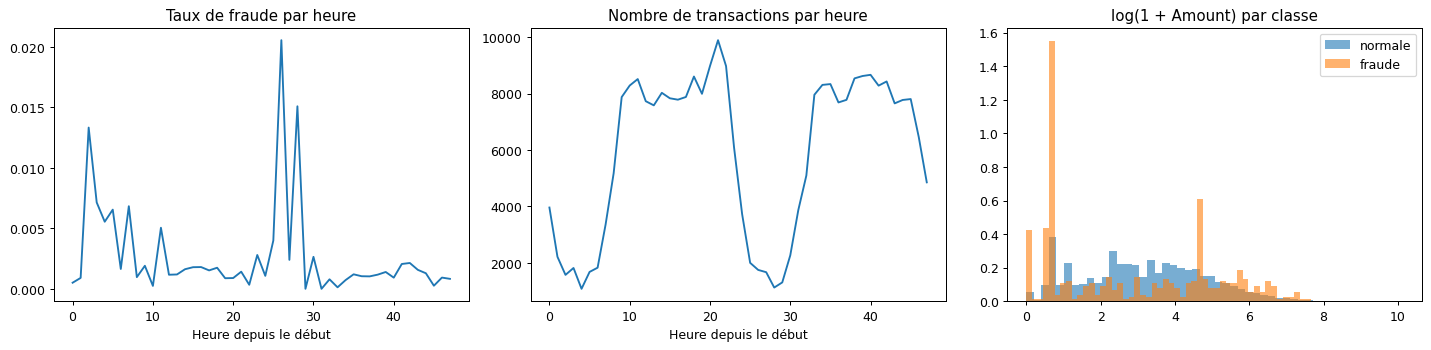

In [6]:
# Une accuracy élevée ne prouve rien : prédire toujours « normale » donne déjà ce score
print(f"Accuracy du classifieur trivial « toujours normale » : {1 - df[CIBLE].mean():.4%}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
heure = (df['Time'] // 3600).astype(int)
df.groupby(heure)[CIBLE].mean().plot(ax=axes[0], title='Taux de fraude par heure')
axes[0].set_xlabel('Heure depuis le début')
df.groupby(heure).size().plot(ax=axes[1], title='Nombre de transactions par heure')
axes[1].set_xlabel('Heure depuis le début')
for c, lab in [(0, 'normale'), (1, 'fraude')]:
    axes[2].hist(np.log1p(df.loc[df[CIBLE] == c, 'Amount']), bins=50, alpha=0.6, density=True, label=lab)
axes[2].set_title('log(1 + Amount) par classe')
axes[2].legend()
plt.tight_layout()
plt.savefig(RES_DIR / 'exploration.png', dpi=120)
plt.show()

## 2. Préparer

### 2.1 Coupure chronologique 70/15/15

On trie par `Time` puis on coupe. Une coupure est **déplacée jusqu'au prochain changement de timestamp**
pour qu'un même `Time` ne soit jamais réparti entre deux partitions. La fréquence naturelle de fraude est conservée
(aucun rééquilibrage en validation/test).

In [7]:
def coupure_chronologique(data, fractions):
    data = data.sort_values('Time', kind='mergesort').reset_index(drop=True)
    temps = data['Time'].to_numpy()
    n = len(data)

    def frontiere(i):
        # Avance l'indice tant que le timestamp est identique au précédent
        while 0 < i < n and temps[i] == temps[i - 1]:
            i += 1
        return i

    i1 = frontiere(int(n * fractions[0]))
    i2 = frontiere(int(n * (fractions[0] + fractions[1])))
    return data.iloc[:i1], data.iloc[i1:i2], data.iloc[i2:]


train_df, val_df, test_df = coupure_chronologique(df, CFG['fractions'])

# Contrôles : partitions disjointes dans le temps et couvrant tout le jeu
assert train_df['Time'].max() < val_df['Time'].min()
assert val_df['Time'].max() < test_df['Time'].min()
assert len(train_df) + len(val_df) + len(test_df) == len(df)

resume_partitions = pd.DataFrame({
    nom: {'lignes': len(p), 'fraudes': int(p[CIBLE].sum()), 'taux_fraude': p[CIBLE].mean(),
          'time_min': p['Time'].min(), 'time_max': p['Time'].max()}
    for nom, p in [('train', train_df), ('validation', val_df), ('test', test_df)]
}).T
resume_partitions.to_csv(RES_DIR / 'partitions.csv')
resume_partitions

,lignes,fraudes,taux_fraude,time_min,time_max
train,199364.0,384.0,0.001926,0.0,132928.0
validation,42722.0,56.0,0.001311,132929.0,151328.0
test,42721.0,52.0,0.001217,151329.0,172792.0


### 2.2 Mise à l'échelle et poids de classe (train uniquement)

In [8]:
scaler = StandardScaler().fit(train_df[FEATURES])


def vers_numpy(p):
    return scaler.transform(p[FEATURES]).astype(np.float32), p[CIBLE].to_numpy().astype(np.float32)


X_tr, y_tr = vers_numpy(train_df)
X_va, y_va = vers_numpy(val_df)
X_te, y_te = vers_numpy(test_df)

# pos_weight = nb_normales / nb_fraudes, calculé sur le train seulement
POS_WEIGHT = float((y_tr == 0).sum() / (y_tr == 1).sum())
print(f'pos_weight (train) = {POS_WEIGHT:.1f}')

# Tenseurs sur le device (le jeu tient en mémoire GPU)
T = {nom: (torch.tensor(X, device=DEVICE), torch.tensor(y, device=DEVICE))
     for nom, X, y in [('train', X_tr, y_tr), ('val', X_va, y_va), ('test', X_te, y_te)]}

pos_weight (train) = 518.2


### 2.3 Outils d'évaluation et règle de seuil

- **Average Precision** (aire sous la courbe précision-rappel) : résume le *classement* des fraudes, indépendamment du seuil.
- **Seuil** : il transforme le classement en *alertes*. Règle figée : **seuil qui maximise le F1 sur la validation**.
  Les résultats au seuil 0,5 sont aussi rapportés pour montrer l'effet du seuil, sans jamais le régler sur le test.

In [9]:
def choisir_seuil(y, p):
    precision, rappel, seuils = precision_recall_curve(y, p)
    f1 = 2 * precision[:-1] * rappel[:-1] / (precision[:-1] + rappel[:-1] + 1e-12)
    return float(seuils[np.nanargmax(f1)])


def evaluer(y, p, seuil):
    pred = (p >= seuil).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        'AP': average_precision_score(y, p),
        'seuil': seuil,
        'precision': precision_score(y, pred, zero_division=0),
        'rappel': recall_score(y, pred, zero_division=0),
        'F1': f1_score(y, pred, zero_division=0),
        'TP': int(tp), 'FP': int(fp), 'FN': int(fn), 'TN': int(tn),
    }


PROBAS = {}   # nom du modèle -> {'val': probas, 'test': probas}

### 2.4 Référence 1 : régression logistique

In [10]:
# class_weight='balanced' est calculé sur les données d'ajustement, c'est-à-dire le train uniquement
logreg = LogisticRegression(class_weight='balanced', max_iter=2000, random_state=CFG['seed'])
logreg.fit(X_tr, y_tr)
PROBAS['Régression logistique'] = {'val': logreg.predict_proba(X_va)[:, 1],
                                   'test': logreg.predict_proba(X_te)[:, 1]}
ap_val_logreg = average_precision_score(y_va, PROBAS['Régression logistique']['val'])
journaliser_run('Régression logistique', {'architecture': 'LogisticRegression', 'class_weight': 'balanced',
                                          'max_iter': 2000, 'seed': CFG['seed']},
                metriques={'ap_val': float(ap_val_logreg)})
print('AP validation :', round(ap_val_logreg, 4))

AP validation : 0.8394


## 3. Construire

### 3.1 Modèles PyTorch

Tous les modèles renvoient des logits de forme `(batch, k)` : `k = 1` pour le MLP, `k = 4` pour TabM.
- **Entraînement** : la BCE est calculée sur chacune des `k` sorties puis moyennée (on optimise la moyenne des pertes,
  pas la perte de la moyenne).
- **Inférence** : on moyenne les **probabilités** sigmoïdes des `k` sorties (pas les logits).

In [11]:
class MLP(nn.Module):
    # MLP 30-64-64-1 avec ReLU et dropout 0,1
    def __init__(self, d_in, hidden, dropout):
        super().__init__()
        couches, d = [], d_in
        for h in hidden:
            couches += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(dropout)]
            d = h
        couches.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*couches)

    def forward(self, x):
        return self.net(x)                    # (batch, 1)


class TabMBinaire(nn.Module):
    # Enveloppe du TabM officiel : sortie (batch, k, 1) -> (batch, k)
    def __init__(self, d_in, **params):
        super().__init__()
        self.tabm = TabM.make(n_num_features=d_in, **params)

    def forward(self, x):
        return self.tabm(x).squeeze(-1)       # (batch, k)


def nb_parametres(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


D_IN = len(FEATURES)
print('Paramètres MLP  :', nb_parametres(MLP(D_IN, **CFG['mlp'])))
print('Paramètres TabM :', nb_parametres(TabMBinaire(D_IN, **CFG['tabm'])))

Paramètres MLP  : 6209
Paramètres TabM : 7676


### 3.2 Boucle d'entraînement avec reprise depuis checkpoint

À chaque époque, l'état complet est sauvegardé dans `last.pt` (modèle, optimiseur, générateurs aléatoires, historique),
et le meilleur modèle sur l'**AP de validation** dans `best.pt`. Si la session Colab coupe, relancer la cellule reprend
l'entraînement là où il s'était arrêté ; si l'entraînement est terminé, le meilleur modèle est simplement rechargé.

In [12]:
@torch.no_grad()
def predire(model, X, batch_size=8192):
    model.eval()
    sorties = [torch.sigmoid(model(X[i:i + batch_size])).mean(dim=1) for i in range(0, len(X), batch_size)]
    return torch.cat(sorties).cpu().numpy()


def entrainer(nom, construire, pos_weight, arch):
    dossier = CKPT_DIR / nom
    dossier.mkdir(parents=True, exist_ok=True)
    fixer_seed(CFG['seed'])
    model = construire().to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=CFG['weight_decay'])
    pw = None if pos_weight is None else torch.tensor([pos_weight], device=DEVICE)
    perte = nn.BCEWithLogitsLoss(pos_weight=pw)
    gen = torch.Generator().manual_seed(CFG['seed'])
    etat = {'epoch': 0, 'best_ap': -1.0, 'patience': 0, 'historique': [], 'termine': False}

    if (dossier / 'last.pt').exists():
        ck = torch.load(dossier / 'last.pt', map_location=DEVICE, weights_only=False)
        model.load_state_dict(ck['model'])
        opt.load_state_dict(ck['opt'])
        gen.set_state(ck['gen'])
        torch.set_rng_state(ck['rng_cpu'])
        if DEVICE.type == 'cuda' and ck['rng_cuda'] is not None:
            torch.cuda.set_rng_state(ck['rng_cuda'])
        etat = ck['etat']
        print(f"[{nom}] reprise après l'époque {etat['epoch']} (meilleure AP val = {etat['best_ap']:.4f})")

    X, y = T['train']
    while not etat['termine'] and etat['epoch'] < CFG['max_epochs']:
        debut = time.time()
        model.train()
        ordre = torch.randperm(len(X), generator=gen).to(DEVICE)
        total = 0.0
        for i in range(0, len(X), CFG['batch_size']):
            idx = ordre[i:i + CFG['batch_size']]
            logits = model(X[idx])                                   # (batch, k)
            loss = perte(logits, y[idx].unsqueeze(1).expand_as(logits))
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item() * len(idx)

        ap_val = average_precision_score(y_va, predire(model, T['val'][0]))
        etat['epoch'] += 1
        etat['historique'].append({'epoch': etat['epoch'], 'loss_train': total / len(X), 'ap_val': float(ap_val)})
        if ap_val > etat['best_ap']:
            etat['best_ap'], etat['patience'] = float(ap_val), 0
            torch.save(model.state_dict(), dossier / 'best.pt')
        else:
            etat['patience'] += 1
        etat['termine'] = etat['patience'] >= CFG['patience'] or etat['epoch'] >= CFG['max_epochs']
        torch.save({'model': model.state_dict(), 'opt': opt.state_dict(), 'gen': gen.get_state(),
                    'rng_cpu': torch.get_rng_state(),
                    'rng_cuda': torch.cuda.get_rng_state() if DEVICE.type == 'cuda' else None,
                    'etat': etat}, dossier / 'last.pt')
        print(f"[{nom}] époque {etat['epoch']:2d} | loss {total / len(X):.4f} | AP val {ap_val:.4f} "
              f"| {time.time() - debut:.1f}s")

    model.load_state_dict(torch.load(dossier / 'best.pt', map_location=DEVICE))
    PROBAS[nom] = {'val': predire(model, T['val'][0]), 'test': predire(model, T['test'][0])}
    params = {'architecture': type(model).__name__, 'pos_weight': pos_weight or 0.0,
              'nb_parametres': nb_parametres(model), **arch,
              **{k: CFG[k] for k in ('lr', 'batch_size', 'weight_decay', 'max_epochs', 'patience', 'seed')}}
    journaliser_run(nom, params, etat['historique'], {'best_ap_val': etat['best_ap']})
    print(f"[{nom}] terminé : meilleure AP val = {etat['best_ap']:.4f}")
    return model, pd.DataFrame(etat['historique'])

### 3.3 Référence 2 : MLP (BCE pondérée)

In [13]:
mlp, hist_mlp = entrainer('MLP', lambda: MLP(D_IN, **CFG['mlp']), POS_WEIGHT, CFG['mlp'])

[MLP] époque  1 | loss 0.5121 | AP val 0.8298 | 1.5s
[MLP] époque  2 | loss 0.3020 | AP val 0.7520 | 1.5s
[MLP] époque  3 | loss 0.2450 | AP val 0.8513 | 1.2s
[MLP] époque  4 | loss 0.2354 | AP val 0.7738 | 1.2s
[MLP] époque  5 | loss 0.2013 | AP val 0.8568 | 1.2s
[MLP] époque  6 | loss 0.1880 | AP val 0.8565 | 1.2s
[MLP] époque  7 | loss 0.1787 | AP val 0.7639 | 1.2s
[MLP] époque  8 | loss 0.1501 | AP val 0.8456 | 1.2s
[MLP] époque  9 | loss 0.1419 | AP val 0.8503 | 1.2s
[MLP] époque 10 | loss 0.1400 | AP val 0.7194 | 1.3s
[MLP] époque 11 | loss 0.1398 | AP val 0.7109 | 1.6s
[MLP] époque 12 | loss 0.1239 | AP val 0.7628 | 1.7s
[MLP] époque 13 | loss 0.1094 | AP val 0.7713 | 1.5s
[MLP] terminé : meilleure AP val = 0.8568


### 3.4 Modèle principal : TabM compact (BCE pondérée)

In [14]:
tabm, hist_tabm = entrainer('TabM pondéré', lambda: TabMBinaire(D_IN, **CFG['tabm']), POS_WEIGHT, CFG['tabm'])

[TabM pondéré] époque  1 | loss 0.5935 | AP val 0.8568 | 5.4s
[TabM pondéré] époque  2 | loss 0.3368 | AP val 0.8537 | 5.7s
[TabM pondéré] époque  3 | loss 0.2896 | AP val 0.8539 | 6.6s
[TabM pondéré] époque  4 | loss 0.2565 | AP val 0.8505 | 6.8s
[TabM pondéré] époque  5 | loss 0.2487 | AP val 0.8495 | 6.1s
[TabM pondéré] époque  6 | loss 0.2303 | AP val 0.8539 | 5.1s
[TabM pondéré] époque  7 | loss 0.2243 | AP val 0.8491 | 4.3s
[TabM pondéré] époque  8 | loss 0.2057 | AP val 0.8484 | 5.6s
[TabM pondéré] époque  9 | loss 0.2132 | AP val 0.8374 | 4.9s
[TabM pondéré] terminé : meilleure AP val = 0.8568


### 3.5 Ablation : TabM sans pondération de la BCE

In [15]:
tabm_np, hist_tabm_np = entrainer('TabM non pondéré', lambda: TabMBinaire(D_IN, **CFG['tabm']), None, CFG['tabm'])

[TabM non pondéré] époque  1 | loss 0.1318 | AP val 0.4239 | 4.5s
[TabM non pondéré] époque  2 | loss 0.0108 | AP val 0.7660 | 4.6s
[TabM non pondéré] époque  3 | loss 0.0059 | AP val 0.8305 | 4.1s
[TabM non pondéré] époque  4 | loss 0.0048 | AP val 0.8465 | 4.1s
[TabM non pondéré] époque  5 | loss 0.0043 | AP val 0.8572 | 4.1s
[TabM non pondéré] époque  6 | loss 0.0041 | AP val 0.8567 | 4.4s
[TabM non pondéré] époque  7 | loss 0.0039 | AP val 0.8609 | 4.6s
[TabM non pondéré] époque  8 | loss 0.0037 | AP val 0.8627 | 4.4s
[TabM non pondéré] époque  9 | loss 0.0035 | AP val 0.8631 | 4.6s
[TabM non pondéré] époque 10 | loss 0.0033 | AP val 0.8636 | 4.4s
[TabM non pondéré] époque 11 | loss 0.0033 | AP val 0.8656 | 4.6s
[TabM non pondéré] époque 12 | loss 0.0032 | AP val 0.8663 | 4.3s
[TabM non pondéré] époque 13 | loss 0.0030 | AP val 0.8690 | 4.5s
[TabM non pondéré] époque 14 | loss 0.0030 | AP val 0.8628 | 4.5s
[TabM non pondéré] époque 15 | loss 0.0030 | AP val 0.8658 | 4.5s
[TabM non 

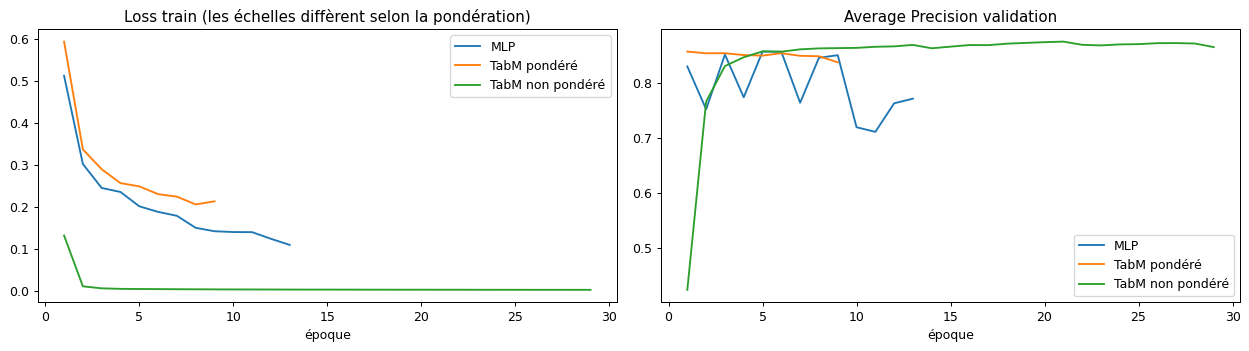

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for nom, h in [('MLP', hist_mlp), ('TabM pondéré', hist_tabm), ('TabM non pondéré', hist_tabm_np)]:
    axes[0].plot(h['epoch'], h['loss_train'], label=nom)
    axes[1].plot(h['epoch'], h['ap_val'], label=nom)
axes[0].set_title('Loss train (les échelles diffèrent selon la pondération)')
axes[1].set_title('Average Precision validation')
for a in axes:
    a.set_xlabel('époque')
    a.legend()
plt.tight_layout()
plt.savefig(RES_DIR / 'courbes_entrainement.png', dpi=120)
plt.show()

## 4. Comparer

### 4.1 Courbes précision-rappel et seuils figés sur la validation

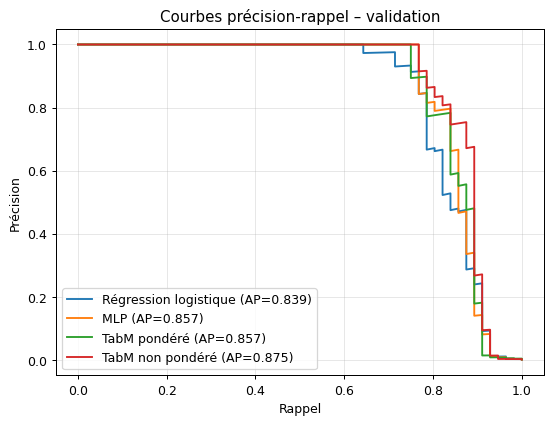

Régression logistique    0.999993
MLP                      0.996990
TabM pondéré             0.997072
TabM non pondéré         0.498910
Name: seuil figé (validation), dtype: float64

In [17]:
SEUILS = {nom: choisir_seuil(y_va, p['val']) for nom, p in PROBAS.items()}

plt.figure(figsize=(7, 5))
for nom, p in PROBAS.items():
    precision, rappel, _ = precision_recall_curve(y_va, p['val'])
    plt.plot(rappel, precision, label=f"{nom} (AP={average_precision_score(y_va, p['val']):.3f})")
plt.xlabel('Rappel')
plt.ylabel('Précision')
plt.title('Courbes précision-rappel – validation')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(RES_DIR / 'pr_validation.png', dpi=120)
plt.show()

with open(RES_DIR / 'seuils.json', 'w') as f:
    json.dump(SEUILS, f, indent=2, ensure_ascii=False)
pd.Series(SEUILS, name='seuil figé (validation)')

### 4.2 Résultats sur le test

Le test n'est utilisé **qu'ici**, une seule fois, avec les seuils déjà figés.

In [18]:
lignes = []
for nom, p in PROBAS.items():
    for regle, seuil in [('seuil validation', SEUILS[nom]), ('seuil 0,5', 0.5)]:
        lignes.append({'modèle': nom, 'règle': regle, **evaluer(y_te, p['test'], seuil)})
resultats = pd.DataFrame(lignes).set_index(['modèle', 'règle'])
resultats.to_csv(RES_DIR / 'resultats_test.csv')
print(f"Fraudes dans le test : {int(y_te.sum())} sur {len(y_te)} transactions")

# Métriques de test au seuil figé, ajoutées au run MLflow de chaque modèle
if USE_MLFLOW:
    for nom in PROBAS:
        r = resultats.loc[(nom, 'seuil validation')]
        with mlflow.start_run(run_id=RUNS[nom]):
            mlflow.log_metrics({f'test_{k}': float(r[k]) for k in ('AP', 'precision', 'rappel', 'F1', 'TP', 'FP', 'FN')})
            mlflow.log_metric('seuil', SEUILS[nom])
resultats.style.format({'AP': '{:.4f}', 'seuil': '{:.4f}', 'precision': '{:.3f}', 'rappel': '{:.3f}', 'F1': '{:.3f}'})

Fraudes dans le test : 52 sur 42721 transactions


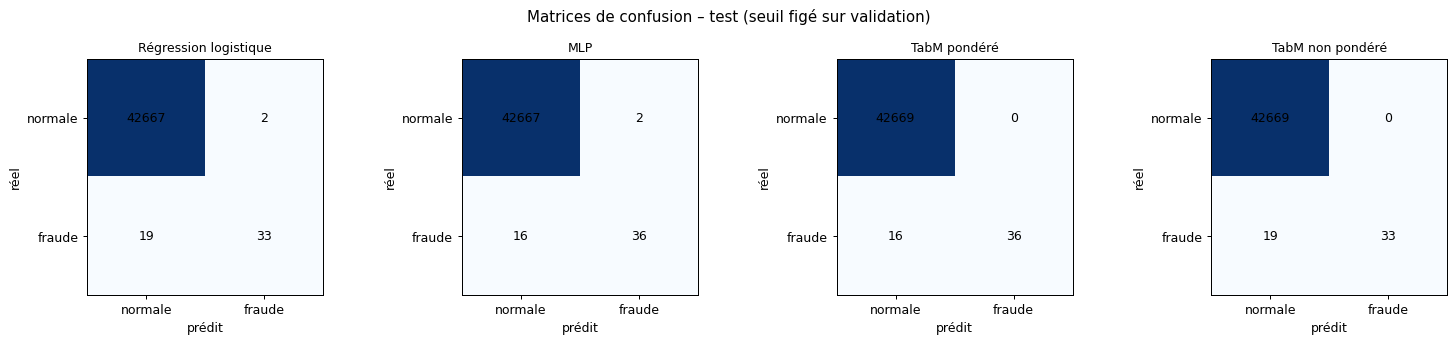

In [19]:
fig, axes = plt.subplots(1, len(PROBAS), figsize=(4.2 * len(PROBAS), 3.8))
for ax, (nom, p) in zip(axes, PROBAS.items()):
    cm = confusion_matrix(y_te, (p['test'] >= SEUILS[nom]).astype(int), labels=[0, 1])
    ax.imshow(cm, cmap='Blues')
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha='center', va='center', color='black')
    ax.set_xticks([0, 1], ['normale', 'fraude'])
    ax.set_yticks([0, 1], ['normale', 'fraude'])
    ax.set_xlabel('prédit')
    ax.set_ylabel('réel')
    ax.set_title(nom, fontsize=10)
plt.suptitle('Matrices de confusion – test (seuil figé sur validation)')
plt.tight_layout()
plt.savefig(RES_DIR / 'matrices_confusion.png', dpi=120)
plt.show()

## 5. Restituer

### 5.1 Analyse des erreurs : fraudes manquées et fausses alertes

In [20]:
montant_te = test_df['Amount'].to_numpy()
analyse = []
for nom, p in PROBAS.items():
    pred = p['test'] >= SEUILS[nom]
    fn = (y_te == 1) & ~pred
    tp = (y_te == 1) & pred
    fp = (y_te == 0) & pred
    analyse.append({
        'modèle': nom,
        'fraudes manquées': int(fn.sum()),
        'montant fraudes manquées': montant_te[fn].sum(),
        'montant fraudes détectées': montant_te[tp].sum(),
        'fausses alertes': int(fp.sum()),
        'fausses alertes / 1000 transactions normales': 1000 * fp.sum() / (y_te == 0).sum(),
    })
pd.DataFrame(analyse).set_index('modèle').round(2)

,fraudes manquées,montant fraudes manquées,montant fraudes détectées,fausses alertes,fausses alertes / 1000 transactions normales
modèle,,,,,
Régression logistique,19,3069.81,3099.07,2,0.05
MLP,16,2490.95,3677.93,2,0.05
TabM pondéré,16,2490.95,3677.93,0,0.00
TabM non pondéré,19,2774.57,3394.31,0,0.00


Fraudes manquées par tous les modèles : 16


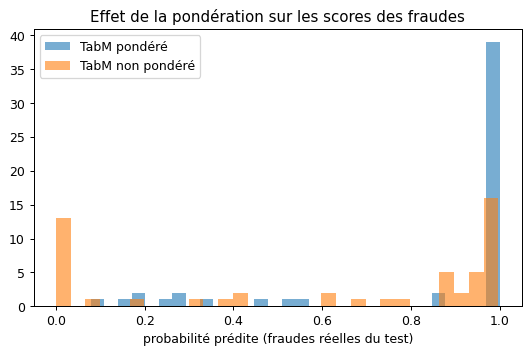

In [21]:
# Les fraudes manquées sont-elles les mêmes pour tous les modèles ?
manquees = {nom: set(np.where((y_te == 1) & (p['test'] < SEUILS[nom]))[0]) for nom, p in PROBAS.items()}
communes = set.intersection(*manquees.values())
print('Fraudes manquées par tous les modèles :', len(communes))

# Effet de la pondération : distribution des probabilités prédites sur les fraudes du test
plt.figure(figsize=(7, 4))
for nom in ['TabM pondéré', 'TabM non pondéré']:
    plt.hist(PROBAS[nom]['test'][y_te == 1], bins=30, alpha=0.6, label=nom)
plt.xlabel('probabilité prédite (fraudes réelles du test)')
plt.title('Effet de la pondération sur les scores des fraudes')
plt.legend()
plt.savefig(RES_DIR / 'effet_ponderation.png', dpi=120)
plt.show()

### 5.2 Sauvegarde de la configuration

In [22]:
with open(RES_DIR / 'config.json', 'w') as f:
    json.dump({**CFG, 'pos_weight_train': POS_WEIGHT, 'features': FEATURES,
               'torch': torch.__version__}, f, indent=2, ensure_ascii=False)
print('Fichiers produits :', sorted(p.name for p in RES_DIR.iterdir()))

Fichiers produits : ['config.json', 'courbes_entrainement.png', 'effet_ponderation.png', 'exploration.png', 'matrices_confusion.png', 'partitions.csv', 'pr_validation.png', 'resultats_test.csv', 'seuils.json']


### 5.3 Export du modèle pour le déploiement

Le modèle principal (**TabM pondéré**) est exporté dans `modele/` avec tout ce qu'il faut pour prédire hors du notebook :
poids, paramètres de mise à l'échelle du train, seuil figé sur la validation et métriques de test.
Ce dossier est utilisé par l'API FastAPI (`api/`) et l'application Streamlit (`app/`).

In [23]:
MODELE_DEPLOYE = 'TabM pondéré'
EXPORT_DIR = RACINE / 'modele'
EXPORT_DIR.mkdir(exist_ok=True)

torch.save(tabm.state_dict(), EXPORT_DIR / 'tabm_pondere.pt')
ligne = resultats.loc[(MODELE_DEPLOYE, 'seuil validation')]
metadonnees = {
    'nom': MODELE_DEPLOYE,
    'version': time.strftime('%Y-%m-%d'),
    'fichier_poids': 'tabm_pondere.pt',
    'features': FEATURES,
    'd_in': D_IN,
    'architecture': CFG['tabm'],
    'scaler_mean': scaler.mean_.tolist(),
    'scaler_scale': scaler.scale_.tolist(),
    'seuil': SEUILS[MODELE_DEPLOYE],
    'regle_seuil': CFG['regle_seuil'],
    'partition_test_time_min': float(test_df['Time'].min()),
    'metriques_test': {k: float(ligne[k]) for k in ('AP', 'precision', 'rappel', 'F1', 'TP', 'FP', 'FN', 'TN')},
    'torch': torch.__version__,
}
with open(EXPORT_DIR / 'modele.json', 'w', encoding='utf-8') as f:
    json.dump(metadonnees, f, indent=2, ensure_ascii=False)

if USE_MLFLOW:
    with mlflow.start_run(run_id=RUNS[MODELE_DEPLOYE]):
        mlflow.set_tag('deploye', 'oui')
        mlflow.log_artifacts(str(EXPORT_DIR), 'modele')
        mlflow.log_artifacts(str(RES_DIR), 'resultats')

print('Modèle exporté :', sorted(p.name for p in EXPORT_DIR.iterdir()))

Modèle exporté : ['modele.json', 'tabm_pondere.pt']


### 5.4 Conclusion (à rédiger à partir des résultats)

- **Classement (AP)** : TabM améliore-t-il l'AP par rapport au MLP et à la régression logistique ? L'écart est-il important au regard du petit nombre de fraudes du test ?
- **Décisions (seuil figé)** : quel compromis entre fraudes manquées et fausses alertes pour chaque modèle ? Comparer avec les résultats au seuil 0,5.
- **Ablation** : quel est l'effet de la pondération de la BCE sur l'AP, sur la distribution des scores et sur le seuil choisi ?
- **Erreurs** : les fraudes manquées sont-elles communes à tous les modèles ? Sont-elles de petit ou de gros montant ?
- **Limites** : un seul découpage temporel, environ deux jours de données, peu de fraudes en test, variables anonymisées, et `Time` hors de la plage du train pour le test.